# 01b · EDA and data checks (Person A)

Run **after** `01_prepare_dataset.ipynb`. Reads `outputs/dataset/` and answers:

1. How many images per letter, per writer, per split?
2. Are the splits balanced, and is there writer leakage?
3. Are there bad crops (blank, too much ink, near-duplicates)?
4. What are the pixel mean/std (train only) to hand to Person B?

It also writes `data/classes.json` and `data/dataset_stats.json`. Bad crops go into `data/exclude.csv`.

In [2]:
import sys, json, hashlib
from pathlib import Path
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import data as D

df = D.load_labels()
print(f"{len(df)} images, {df.writer_id.nunique()} writers, {df.label_id.nunique()} classes")
D.write_classes_json()
df.head()

825 images, 18 writers, 33 classes


,filepath,label_id,letter,romanization,writer_id,sheet_no,source_file,source_page,split
0,images/00_ka/w01_s1_00.png,0,ក,ka,w01,1,scan_001.pdf,1,train
1,images/01_kha/w01_s1_01.png,1,ខ,kha,w01,1,scan_001.pdf,1,train
2,images/02_ko/w01_s1_02.png,2,គ,ko,w01,1,scan_001.pdf,1,train
3,images/03_kho/w01_s1_03.png,3,ឃ,kho,w01,1,scan_001.pdf,1,train
4,images/04_ngo/w01_s1_04.png,4,ង,ngo,w01,1,scan_001.pdf,1,train


## 1. Class balance

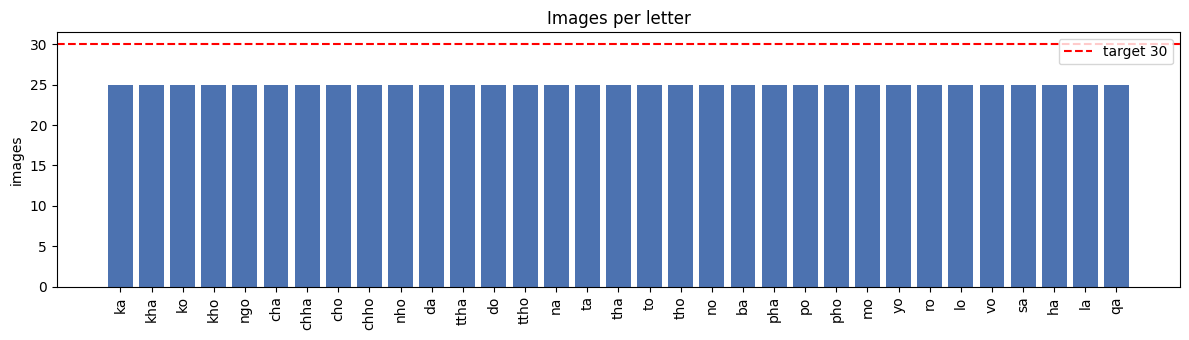

min / median / max per class: 25 25.0 25
Classes below 30: ['ka', 'kha', 'ko', 'kho', 'ngo', 'cha', 'chha', 'cho', 'chho', 'nho', 'da', 'ttha', 'do', 'ttho', 'na', 'ta', 'tha', 'to', 'tho', 'no', 'ba', 'pha', 'po', 'pho', 'mo', 'yo', 'ro', 'lo', 'vo', 'sa', 'ha', 'la', 'qa']


In [3]:
counts = df.groupby(["label_id", "romanization"]).size().reset_index(name="n")
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(counts.romanization, counts.n, color="#4C72B0")
ax.axhline(30, color="red", ls="--", label="target 30")
ax.set_ylabel("images"); ax.set_title("Images per letter"); ax.legend()
plt.xticks(rotation=90); plt.tight_layout(); plt.show()
print("min / median / max per class:", counts.n.min(), counts.n.median(), counts.n.max())
print("Classes below 30:", counts[counts.n < 30].romanization.tolist() or "none")

## 2. Writers and splits

In [4]:
per_writer = df.groupby(["writer_id", "split"]).size().rename("images").reset_index()
print(per_writer.to_string(index=False))
print()
split_tbl = df.groupby("split").agg(writers=("writer_id", "nunique"), images=("filepath", "size"))
split_tbl["share_%"] = (100 * split_tbl.images / split_tbl.images.sum()).round(1)
print(split_tbl)

# Leakage check: a writer must be in exactly one split
leak = df.groupby("writer_id").split.nunique()
assert (leak == 1).all(), f"LEAK: writers in several splits: {leak[leak > 1].index.tolist()}"
print("\nNo writer appears in more than one split.")

# Every class should appear in every split
cls_split = df.pivot_table(index="label_id", columns="split", values="filepath", aggfunc="size", fill_value=0)
print("Classes missing from a split:", cls_split[(cls_split == 0).any(axis=1)].index.tolist() or "none")
cls_split.T

writer_id split  images
      w01 train      66
      w02 train      33
      w03 train      33
      w04 train      33
      w05   val      33
      w06  test      33
      w07 train      33
      w08  test      33
      w09 train      66
      w10  test     132
      w11 train      66
      w12 train      33
      w13   val      33
      w14   val      33
      w15 train      33
      w16 train      33
      w17 train      33
      w18 train      66

       writers  images  share_%
split                          
test         3     198     24.0
train       12     528     64.0
val          3      99     12.0

No writer appears in more than one split.
Classes missing from a split: none


label_id,0,1,2,3,4,5,6,7,8,9,...,23,24,25,26,27,28,29,30,31,32
split,,,,,,,,,,,,,,,,,,,,,
test,6,6,6,6,6,6,6,6,6,6,...,6,6,6,6,6,6,6,6,6,6
train,16,16,16,16,16,16,16,16,16,16,...,16,16,16,16,16,16,16,16,16,16
val,3,3,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3


## 3. Find bad crops

Three automatic checks. Then look at the flagged images and decide.

* **Ink fraction** (share of dark pixels): too low means almost blank, too high means a smudge or a border line.
* **Exact duplicates** (same pixels): the same sheet scanned or listed twice.
* **Outliers inside a class**: far from the average image of that letter.

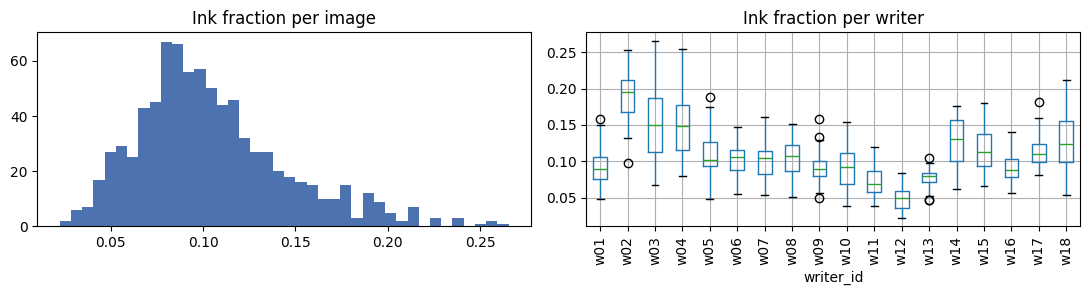

1st / 99th percentile of ink fraction: 0.035 / 0.227
Exact duplicate images: 0


,filepath,writer_id,hash


In [5]:
imgs = np.stack([D.load_image(D.DATASET_DIR / f) for f in df.filepath])      # (N, 64, 64), ink = 1
df["ink"] = imgs.mean(axis=(1, 2))
df["hash"] = [hashlib.md5(((a > 0.5).astype(np.uint8)).tobytes()).hexdigest() for a in imgs]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(df.ink, bins=40, color="#4C72B0"); ax[0].set_title("Ink fraction per image")
df.boxplot(column="ink", by="writer_id", ax=ax[1], rot=90); ax[1].set_title("Ink fraction per writer"); plt.suptitle("")
plt.tight_layout(); plt.show()

lo, hi = df.ink.quantile(0.01), df.ink.quantile(0.99)
print(f"1st / 99th percentile of ink fraction: {lo:.3f} / {hi:.3f}")
dups = df[df.duplicated("hash", keep=False)].sort_values("hash")
print("Exact duplicate images:", len(dups))
dups[["filepath", "writer_id", "hash"]].head(20)

30 images flagged for a manual look


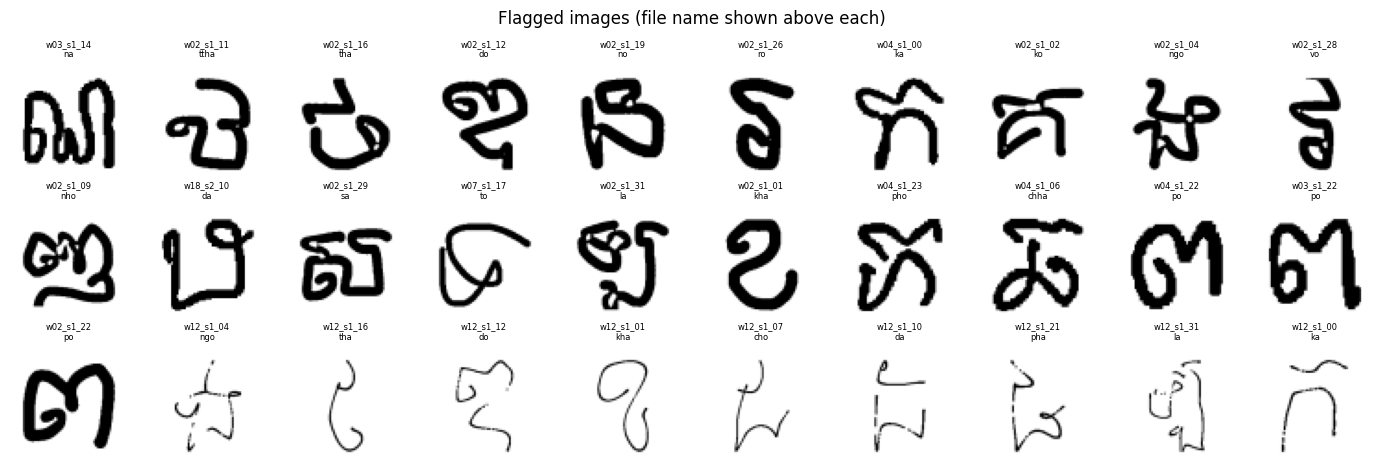

In [6]:
# Distance from the class mean image (a high value = looks unlike other examples of that letter)
means = np.stack([imgs[df.label_id.values == k].mean(axis=0) for k in range(33)])
df["dist"] = np.sqrt(((imgs - means[df.label_id.values]) ** 2).mean(axis=(1, 2)))
df["z"] = df.groupby("label_id").dist.transform(lambda s: (s - s.mean()) / s.std())

flag = df[(df.z > 2.5) | (df.ink < lo) | (df.ink > hi)].sort_values("z", ascending=False)
print(f"{len(flag)} images flagged for a manual look")

def show(rows, ncols=10, title=""):
    rows = rows.head(ncols * 6)
    nrows = int(np.ceil(len(rows) / ncols)) or 1
    fig, axes = plt.subplots(nrows, ncols, figsize=(1.4 * ncols, 1.6 * nrows), squeeze=False)
    for a in axes.ravel(): a.axis("off")
    for a, (_, r) in zip(axes.ravel(), rows.iterrows()):
        a.imshow(cv2.imread(str(D.DATASET_DIR / r.filepath), 0), cmap="gray")
        a.set_title(f"{Path(r.filepath).stem}\n{r.romanization}", fontsize=6)
    plt.suptitle(title); plt.tight_layout(); plt.show()

show(flag, title="Flagged images (file name shown above each)")

### Record bad crops

Look at the grid above. For every image that is clearly **bad** (blank, crossed out, wrong letter, border lines, cut off), add its file name to the list below. Leave unusual-but-valid handwriting in: the model should learn it.

The list is saved to `data/exclude.csv` (in Git), so **everyone** skips these images and a rebuild never brings them back.

In [7]:
BAD = {
    # "w05_s1_12.png": "blank box",
    # "w09_s2_30.png": "crossed out",
}

ex = pd.DataFrame({"filename": list(BAD), "reason": list(BAD.values())})
with open(D.EXCLUDE_CSV, "w", encoding="utf-8") as f:
    f.write("# Bad crops to leave out of training. One file name per line (name only, e.g. w05_s1_12.png).\n")
    f.write("# Applied by src/data.py and the EDA notebook. Edit the BAD dict in notebooks/01b_eda.ipynb.\n")
    ex.to_csv(f, index=False)
print(f"{len(ex)} images excluded -> data/exclude.csv  (re-run the first cell to apply)")

0 images excluded -> data/exclude.csv  (re-run the first cell to apply)


## 4. What does each letter look like on average?

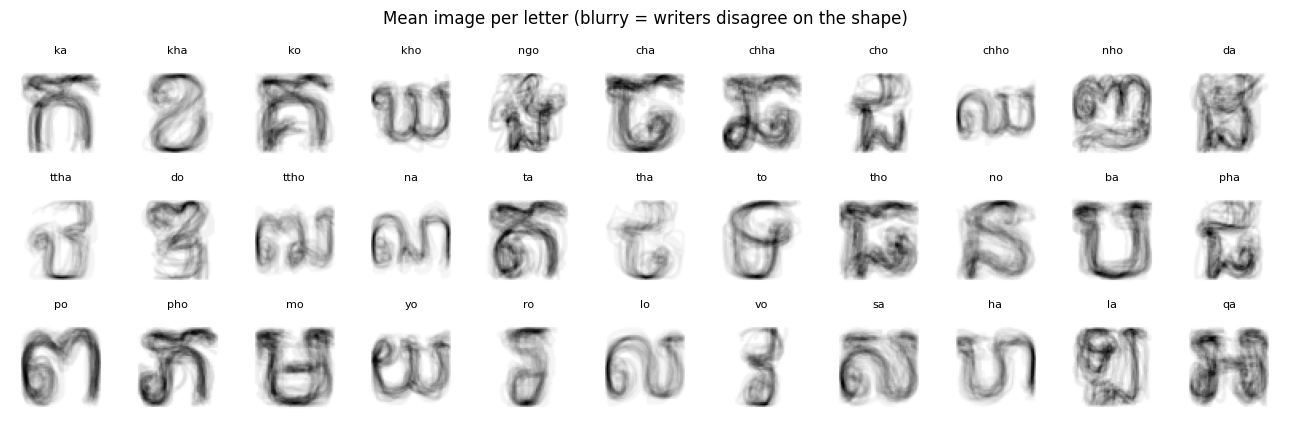

In [8]:
fig, axes = plt.subplots(3, 11, figsize=(13, 4.4))
for k, a in enumerate(axes.ravel()):
    a.imshow(means[k], cmap="gray_r"); a.set_title(D.ROMAN[k], fontsize=8); a.axis("off")
plt.suptitle("Mean image per letter (blurry = writers disagree on the shape)"); plt.tight_layout(); plt.show()

## 5. Stats to hand over

The mean and std must come from the **train split only**.

In [9]:
train = (df.split == "train").values
mean, std = float(imgs[train].mean()), float(imgs[train].std())
stats = {
    "image_size": D.IMG_SIZE,
    "num_classes": D.NUM_CLASSES,
    "pixel_format": "float32 in [0, 1], ink = 1, paper = 0",
    "train_mean": round(mean, 4), "train_std": round(std, 4),
    "images": {s: int((df.split == s).sum()) for s in ["train", "val", "test"]},
    "writers": {s: int(df[df.split == s].writer_id.nunique()) for s in ["train", "val", "test"]},
    "classes_below_30": counts[counts.n < 30].romanization.tolist(),
    "excluded": len(ex),
}
(ROOT / "data" / "dataset_stats.json").write_text(json.dumps(stats, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(stats, ensure_ascii=False, indent=2))

{
  "image_size": 64,
  "num_classes": 33,
  "pixel_format": "float32 in [0, 1], ink = 1, paper = 0",
  "train_mean": 0.1084,
  "train_std": 0.2887,
  "images": {
    "train": 528,
    "val": 99,
    "test": 198
  },
  "writers": {
    "train": 12,
    "val": 3,
    "test": 3
  },
  "classes_below_30": [
    "ka",
    "kha",
    "ko",
    "kho",
    "ngo",
    "cha",
    "chha",
    "cho",
    "chho",
    "nho",
    "da",
    "ttha",
    "do",
    "ttho",
    "na",
    "ta",
    "tha",
    "to",
    "tho",
    "no",
    "ba",
    "pha",
    "po",
    "pho",
    "mo",
    "yo",
    "ro",
    "lo",
    "vo",
    "sa",
    "ha",
    "la",
    "qa"
  ],
  "excluded": 0
}


## 6. Augmentation preview

What Person B's training will see. Rotation, shift, zoom and stroke thickness change a little; the letter stays readable.

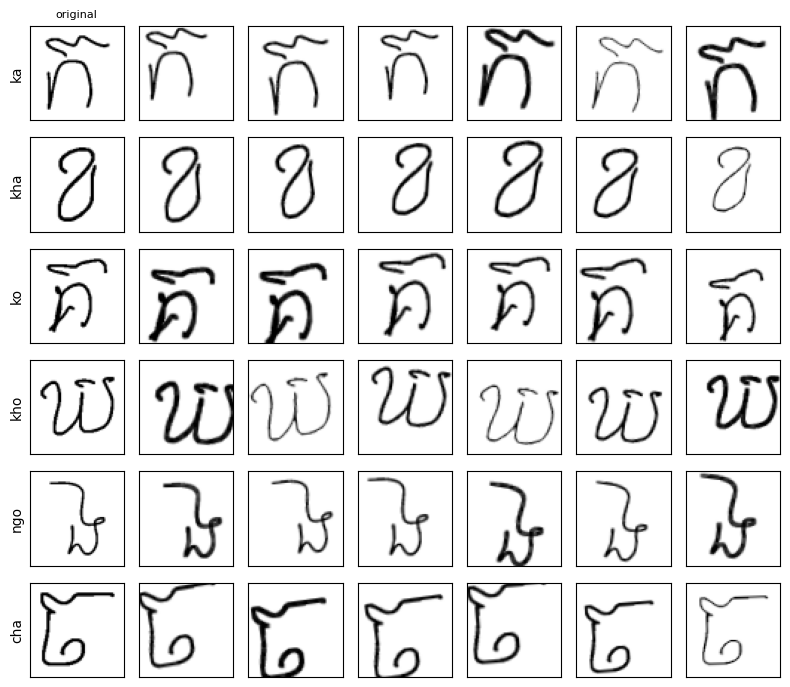

In [10]:
rng = np.random.default_rng(0)
sample = df[(df.split == "train")].groupby("label_id").head(1).head(6)
fig, axes = plt.subplots(6, 7, figsize=(8, 7))
for i, (idx, r) in enumerate(sample.iterrows()):
    axes[i, 0].imshow(imgs[idx], cmap="gray_r"); axes[i, 0].set_ylabel(r.romanization)
    for j in range(1, 7):
        axes[i, j].imshow(D.augment(imgs[idx], rng), cmap="gray_r")
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])
axes[0, 0].set_title("original", fontsize=8); plt.tight_layout(); plt.show()

## 7. Check the demo-app preprocessing

`D.preprocess_drawing` turns a canvas drawing into the same format as the training images. Below we fake a canvas drawing from a real letter (thick white-on-black strokes) and check it comes back looking like the original.

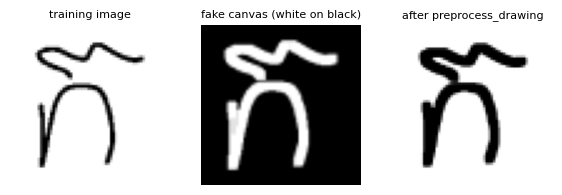

shape (64, 64) | range 0.0 1.0


In [11]:
x = imgs[0]
fake = cv2.dilate((x * 255).astype(np.uint8), np.ones((3, 3), np.uint8))          # thick white ink ...
fake = cv2.resize(fake, (300, 300), interpolation=cv2.INTER_LINEAR)                # ... on black, any size
out = D.preprocess_drawing(fake)
fig, ax = plt.subplots(1, 3, figsize=(7, 2.6))
for a, im, t in zip(ax, [x, fake, out], ["training image", "fake canvas (white on black)", "after preprocess_drawing"]):
    a.imshow(im, cmap="gray_r" if im is not fake else "gray"); a.set_title(t, fontsize=8); a.axis("off")
plt.show()
print("shape", out.shape, "| range", out.min(), out.max())

## Hand-off checklist

- [ ] `data/classes.json` written
- [ ] `data/dataset_stats.json` written (mean/std from train only)
- [ ] `data/exclude.csv` filled in after looking at the flagged images
- [ ] No writer leakage (section 2 passes)
- [ ] Classes below 30 images reported to the team
- [ ] Tell B and C: `from src.data import load_split, KhmerDataset, augment, preprocess_drawing`